<a href="https://colab.research.google.com/github/LeyA-1249/Proyecto-CienciadeDatos/blob/main/Proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Introducción:
Este proyecto se realizo con un dataset de 100 mil registros, con nombre ai_job_impact_dataset los cuales son datos sinteticos, se realizo la limpieza, exploración y automatización del mismo.
Se busca responder con este dataset si la habilidad en la tecnología es un factor que nos determine el salario y si nuestro empleo correo algún riesgo a futuro por la posibilidad de automatización.
Realizado por Anna Karen Leyva Ramirez
https://colab.research.google.com/drive/1bWyITgujkRxAjxfbTGpW1K5aFkbzx4Lx?usp=sharing

drive: data set
https://drive.google.com/file/d/1UeXHsppmKQhilcySASKqD2f5bgoDvSkm/view?usp=sharing


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df_Empleo= pd.read_csv('/content/drive/MyDrive/Importantes /tecnochicas/ai_job_impact_dataset.csv')
print(" El archivo se cargó correctamente.")
print(f"El dataset contiene {df_Empleo.shape[0]} filas y {df_Empleo.shape[1]} columnas.\n")
display(df_Empleo.head())
df_Empleo.info()

 El archivo se cargó correctamente.
El dataset contiene 100000 filas y 29 columnas.



,worker_id,country,continent,year,age,gender,education_level,industry,job_role,years_experience,...,training_hours,reskilling_completed,automation_probability,job_satisfaction,promotion_probability,layoff_probability,employment_status_after_ai,annual_performance_rating,mental_stress_score,innovation_score
0,1,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,...,136.0,No,0.4382,8.01,0.5516,0.1362,Employed,4.16,23.29,46.19
1,2,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,...,55.5,Yes,0.4848,8.00,0.4824,0.2122,Employed,3.65,19.45,59.25
2,3,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,...,110.8,No,0.4564,6.11,0.3561,0.1431,Employed,3.42,47.87,16.69
3,4,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,...,109.7,Yes,0.6871,5.64,0.3547,0.2724,Employed,3.77,38.92,39.84
4,5,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,...,71.3,Yes,0.3714,9.68,0.4796,0.1333,Employed,3.79,27.33,47.53


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 29 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   worker_id                   100000 non-null  int64  
 1   country                     100000 non-null  object 
 2   continent                   97908 non-null   object 
 3   year                        100000 non-null  int64  
 4   age                         97973 non-null   float64
 5   gender                      97996 non-null   object 
 6   education_level             97999 non-null   object 
 7   industry                    98006 non-null   object 
 8   job_role                    97949 non-null   object 
 9   years_experience            97977 non-null   float64
 10  salary_usd                  97965 non-null   float64
 11  employment_type             97983 non-null   object 
 12  company_size                98012 non-null   object 
 13  remote_work    

#LIMPIEZA DEL DATAFRAME

Realizamos la limpieza del dataframe principal lo que incluye:
* Eliminar valores nulos
* Cambio de nombres de columnas
* Eliminas duplicados
* Eliminar columnas no necesarias
* Reindexar

In [ ]:
#Se empieza la limpieza pero ya no enfocada en México si no general y global
print("--- Valores nulos por columna ---")
print(df_Empleo.isnull().sum())

# 2. Verificar si existen filas completamente duplicadas
duplicados = df_Empleo.duplicated().sum()
print(f"\nNúmero de filas duplicadas en el dataset: {duplicados}")


--- Valores nulos por columna ---
worker_id                        0
country                          0
continent                     2092
year                             0
age                           2027
gender                        2004
education_level               2001
industry                      1994
job_role                      2051
years_experience              2023
salary_usd                    2035
employment_type               2017
company_size                  1988
remote_work                   1926
ai_adoption_level             2002
ai_literacy_score             2011
digital_skill_score           1894
productivity_score            2035
hours_worked_per_week         2036
training_hours                1932
reskilling_completed          2029
automation_probability        1958
job_satisfaction              1948
promotion_probability         1975
layoff_probability            1964
employment_status_after_ai    2007
annual_performance_rating     1941
mental_stress_score  

In [ ]:
#Se realiza la copía de seguridad
df_clean = df_Empleo.copy()
df_clean.head()

,worker_id,country,continent,year,age,gender,education_level,industry,job_role,years_experience,...,training_hours,reskilling_completed,automation_probability,job_satisfaction,promotion_probability,layoff_probability,employment_status_after_ai,annual_performance_rating,mental_stress_score,innovation_score
0,1,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,...,136.0,No,0.4382,8.01,0.5516,0.1362,Employed,4.16,23.29,46.19
1,2,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,...,55.5,Yes,0.4848,8.00,0.4824,0.2122,Employed,3.65,19.45,59.25
2,3,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,...,110.8,No,0.4564,6.11,0.3561,0.1431,Employed,3.42,47.87,16.69
3,4,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,...,109.7,Yes,0.6871,5.64,0.3547,0.2724,Employed,3.77,38.92,39.84
4,5,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,...,71.3,Yes,0.3714,9.68,0.4796,0.1333,Employed,3.79,27.33,47.53


In [ ]:
#Se empiezan manipular los datos
df_clean.drop_duplicates(inplace = True)
revision_duplicado=df_clean.duplicated().sum()
print(f"\n Nuevos Datos duplicados:{revision_duplicado}")
#Se aliminaron499 datos duplicados


 Nuevos Datos duplicados:0


In [ ]:
#En este enfoque nuevo solo eliminaremos :
#annual_performance_rating,mental_stress_score,'job_satisfaction','company_size'
df_nuevo = df_clean.drop(['worker_id','company_size',
                         'annual_performance_rating','mental_stress_score',
                         'job_satisfaction'], axis=1)
df_nuevo.info() #Se borraron 4 columnas al final

<class 'pandas.core.frame.DataFrame'>
Index: 99501 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     99501 non-null  object 
 1   continent                   97416 non-null  object 
 2   year                        99501 non-null  int64  
 3   age                         97482 non-null  float64
 4   gender                      97508 non-null  object 
 5   education_level             97511 non-null  object 
 6   industry                    97516 non-null  object 
 7   job_role                    97459 non-null  object 
 8   years_experience            97481 non-null  float64
 9   salary_usd                  97476 non-null  float64
 10  employment_type             97490 non-null  object 
 11  remote_work                 97585 non-null  object 
 12  ai_adoption_level           97508 non-null  float64
 13  ai_literacy_score           97500 no

In [ ]:

#Ahora vamos a cambiar el nombre de las columnas traducir
df_nuevo2= df_nuevo.rename(columns={'country':'pais',
                         'continent':'continente', 'year': 'año',
                          'age':'edad', 'gender': 'genero', 'education_level': 'nivel_educativo',
                         'industry':'industria','job_role':'rol_trabajo','years_experience':'años_experiencia',
                          'salary_usd':'salario','employment_type':'tipo_empleo','remote_work':'trabajo_remoto','ai_adoption_level':'adopcion_ia',
                          'ai_literacy_score':'conocimiento_ia','digital_skill_score':'habilidad_digital',
                         'productivity_score':'productividad','hours_worked_per_week':'trabajo_semana','training_hours':'tiempo_formacion',
                         'reskilling_completed':'capacitacion_constante','automation_probability':'probabilidad_automatizacion',
                         'promotion_probability':'probabilidad_asenso','layoff_probability':'probabilidad_despido','employment_status_after_ai':'estatus_empleo_ia','innovation_score ':'nivel_inovacion'})
df_nuevo2.head()

,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,habilidad_digital,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,14288.80,...,39.60,64.25,37.7,136.0,No,0.4382,0.5516,0.1362,Employed,46.19
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,92290.01,...,38.48,46.15,41.6,55.5,Yes,0.4848,0.4824,0.2122,Employed,59.25
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,12359.08,...,7.28,38.16,42.3,110.8,No,0.4564,0.3561,0.1431,Employed,16.69
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,15811.44,...,40.89,76.66,40.0,109.7,Yes,0.6871,0.3547,0.2724,Employed,39.84
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,9951.72,...,39.41,64.97,31.3,71.3,Yes,0.3714,0.4796,0.1333,Employed,47.53


In [ ]:
df_nuevo2.isnull().sum(axis=1).value_counts()

print(df_nuevo2.isnull().sum())


pais                              0
continente                     2085
año                               0
edad                           2019
genero                         1993
nivel_educativo                1990
industria                      1985
rol_trabajo                    2042
años_experiencia               2020
salario                        2025
tipo_empleo                    2011
trabajo_remoto                 1916
adopcion_ia                    1993
conocimiento_ia                2001
habilidad_digital              1882
productividad                  2021
trabajo_semana                 2029
tiempo_formacion               1922
capacitacion_constante         2022
probabilidad_automatizacion    1947
probabilidad_asenso            1965
probabilidad_despido           1951
estatus_empleo_ia              1996
innovation_score               1992
dtype: int64


In [ ]:
df_nuevo2.dropna(thresh=23,inplace=True)
print(df_nuevo2.isnull().sum())
print(f"El dataset contiene {df_nuevo2.shape[0]} filas y {df_nuevo2.shape[1]} columnas.\n")

pais                              0
continente                     1357
año                               0
edad                           1356
genero                         1292
nivel_educativo                1342
industria                      1297
rol_trabajo                    1326
años_experiencia               1315
salario                        1318
tipo_empleo                    1325
trabajo_remoto                 1250
adopcion_ia                    1290
conocimiento_ia                1289
habilidad_digital              1177
productividad                  1290
trabajo_semana                 1313
tiempo_formacion               1278
capacitacion_constante         1327
probabilidad_automatizacion    1278
probabilidad_asenso            1275
probabilidad_despido           1231
estatus_empleo_ia              1258
innovation_score               1318
dtype: int64
El dataset contiene 92371 filas y 24 columnas.



En  este paso en la limpieza eliminamos las filas que tengan más de 2 campos vacios por lo que nos quedamos con 92371 filas y 24 columnas

-Llenado de NAN
Se rellenan las filas numericas con el promedio de cada categoria y para las columnas que son objeto se rellena con la moda de cada categoria

In [ ]:
columnas_numericas=df_nuevo2.select_dtypes(include=[np.number]).columns
df_nuevo2[columnas_numericas]=df_nuevo2[columnas_numericas].fillna(df_nuevo2[columnas_numericas].mean())
df_nuevo2[columnas_numericas] = df_nuevo2[columnas_numericas].round(2)
print(df_nuevo2.isnull().sum())

pais                              0
continente                     1357
año                               0
edad                              0
genero                         1292
nivel_educativo                1342
industria                      1297
rol_trabajo                    1326
años_experiencia                  0
salario                           0
tipo_empleo                    1325
trabajo_remoto                 1250
adopcion_ia                       0
conocimiento_ia                   0
habilidad_digital                 0
productividad                     0
trabajo_semana                    0
tiempo_formacion                  0
capacitacion_constante         1327
probabilidad_automatizacion       0
probabilidad_asenso               0
probabilidad_despido              0
estatus_empleo_ia              1258
innovation_score                  0
dtype: int64


In [ ]:
columnas_textuales=df_nuevo2.select_dtypes(include=[object]).columns
df_nuevo2[columnas_textuales]=df_nuevo2[columnas_textuales].fillna(df_nuevo2[columnas_textuales].mode().iloc[0])
print(df_nuevo2.isnull().sum())
#Relleno con moda de los registros que son objeto.
#Ya no tenemos nan
df_nuevo2= df_nuevo2.reset_index(drop=True)

pais                           0
continente                     0
año                            0
edad                           0
genero                         0
nivel_educativo                0
industria                      0
rol_trabajo                    0
años_experiencia               0
salario                        0
tipo_empleo                    0
trabajo_remoto                 0
adopcion_ia                    0
conocimiento_ia                0
habilidad_digital              0
productividad                  0
trabajo_semana                 0
tiempo_formacion               0
capacitacion_constante         0
probabilidad_automatizacion    0
probabilidad_asenso            0
probabilidad_despido           0
estatus_empleo_ia              0
innovation_score               0
dtype: int64


In [ ]:
#Vamos a exportar el dataset limpio y traducido
df_nuevo2.to_csv('dataset_clean.csv',index=False)


FILTRO DE DATOS
---

In [ ]:
#MANERA general
#Vamos a ver si la edad coincide con los años de experiencia
filas_sospecha=[]
for idx, fila in df_nuevo2.iterrows():
    edad=fila['edad']
    años=fila['años_experiencia']
    if edad <= 21 and años >= 3:
        filas_sospecha.append
        #Aquí colocamos 3 años teniendo como general mayoria de edad para laboral 18
print(filas_sospecha)
#Resultado no hay datos erroneos dentro del data set en esto

[]


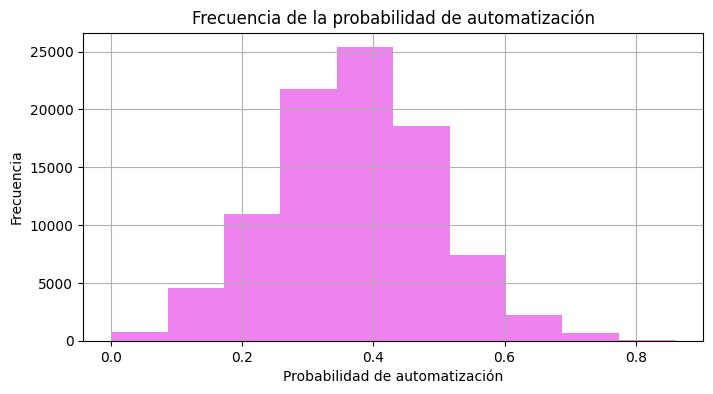

In [ ]:
df_nuevo2['probabilidad_automatizacion'].hist(bins=10, figsize=(8,4), color= 'violet')
plt.title("Frecuencia de la probabilidad de automatización")
plt.xlabel("Probabilidad de automatización")
plt.ylabel("Frecuencia")
plt.show()


Vemos que tenemos más registros que tienen probabilidad del 0.2 al 0.6 de automatización

/tmp/ipykernel_12544/3270988784.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_nuevo2,


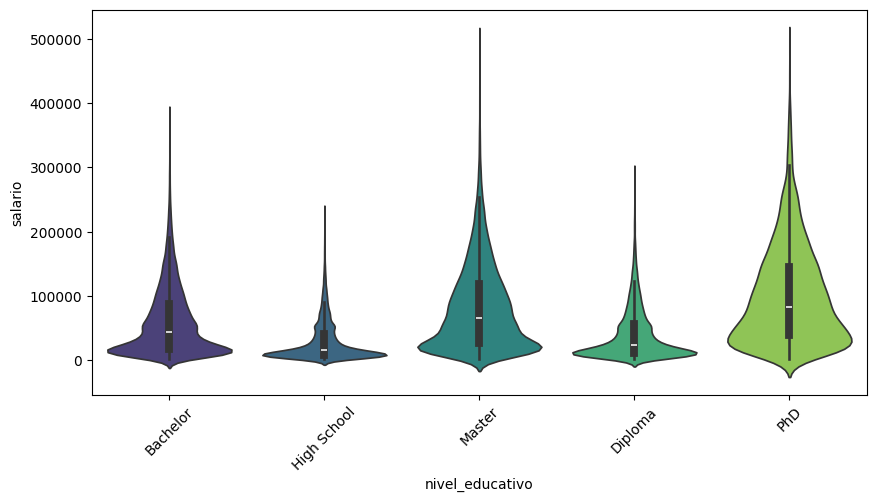

In [ ]:
#Vamos a ver como se distribuye la educación

plt.figure(figsize=(10,5))
sns.violinplot(data=df_nuevo2,
               x="nivel_educativo",
               y="salario",
               palette='viridis')
plt.xticks(rotation=45)
plt.show()

En nuestro dataset contamos con más datos de doctorado, maestria, bachillerato y con salarios de por menos de 100 mil dolares al año lo que se verá más adelante reflejado en los cuartiles.


# Relacion salario

min         1500.00
max       497176.08
mean       53516.40
median     33728.80
Name: salario, dtype: object


/tmp/ipykernel_12544/2664498370.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=salario_outliers, x='salario', palette= 'viridis')


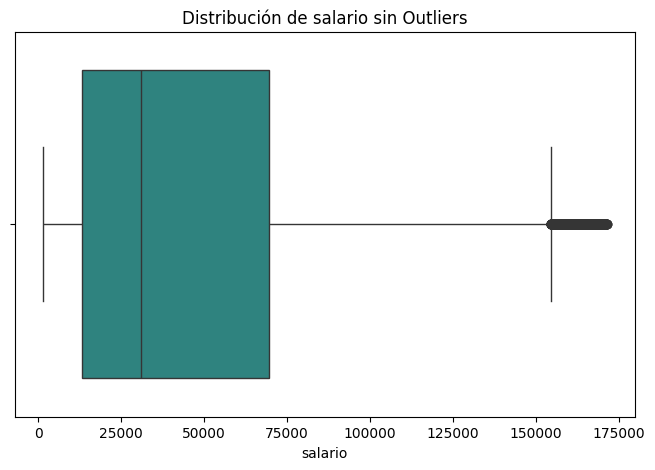

In [ ]:
#En este apartado de salario vamos a verificar como influye
estimacion_salario= df_nuevo2['salario'].agg(['min','max','mean','median']).map('{:.2f}'.format)
print(estimacion_salario)
Q1 = df_nuevo2['salario'].quantile(0.25)
Q3 = df_nuevo2['salario'].quantile(0.75)
IQR= Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 3. Filtrar los datos para conservar solo los valores dentro del rango
salario_outliers  = df_nuevo2[
    (df_nuevo2['salario'] >= limite_inferior) &
    (df_nuevo2['salario'] <= limite_superior)
]
salario_superior = df_nuevo2['salario'] >= limite_inferior
salario_inferior = df_nuevo2['salario'] <= limite_inferior

# 4. Graficar los datos limpios
plt.figure(figsize=(8, 5))
sns.boxplot(data=salario_outliers, x='salario', palette= 'viridis')
plt.title("Distribución de salario sin Outliers")
plt.show()

Aquí podemos observar que nuestro salario registrado esta en un rango de los 20000 dolares por año un poco menos de los 75 mil dolares, pero si tenemos datos extremos que  van arriba de los 150 mil dolares.

salario    adopcion_ia
1500.00    33.41          1
           37.74          1
           50.89          1
           52.17          1
           68.92          1
                         ..
429833.77  100.00         1
440374.73  100.00         1
443867.52  86.79          1
489641.52  92.33          1
497176.08  84.72          1
Name: count, Length: 92101, dtype: int64


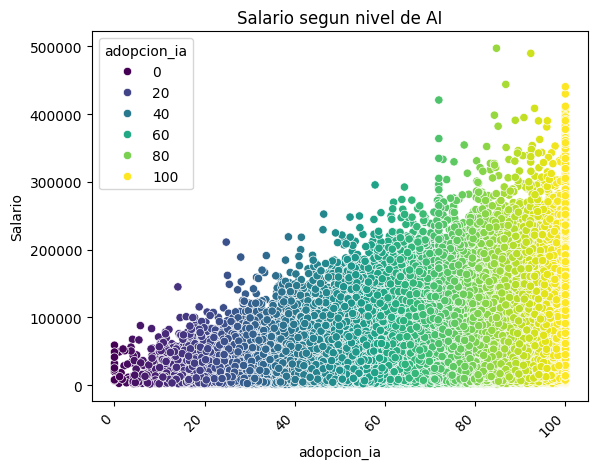

In [ ]:
relacion_salario= df_nuevo2.groupby('salario')['adopcion_ia'].value_counts()
print(relacion_salario)
sns.scatterplot(
    data=df_nuevo2,
    x="adopcion_ia",
    y="salario",
    hue="adopcion_ia",
    palette="viridis",
)

plt.title("Salario segun nivel de AI")
plt.xlabel("adopcion_ia")
plt.ylabel("Salario")
plt.xticks(rotation=45, ha='right')
plt.show()

Aquí se puede visualizar que el salario aumenta si se adopta más la ia, aunque eso es solamente de manera general y sin promediar el salario, ya que si lo agrupamos por pais como se vera más adelante no tiene tanta varianza

In [ ]:
frecuencia_pais=(
    df_nuevo2.groupby('pais').agg(habilidad_pais = ('habilidad_digital', 'mean'), pais_conteo=('pais','count')).reset_index().round()

).sort_values(by='pais_conteo', ascending=False)

display(frecuencia_pais)
Conteo_pais = df_nuevo2["pais"].value_counts().sort_values(ascending=False)
display(Conteo_pais)

,pais,habilidad_pais,pais_conteo
19,India,33.0,5952
50,USA,41.0,5894
8,China,36.0,4961
20,Indonesia,33.0,2988
49,UK,41.0,2912
14,France,41.0,2580
15,Germany,41.0,2536
31,Nigeria,32.0,2533
35,Philippines,33.0,2503
24,Japan,41.0,2491


,count
pais,
India,5952
USA,5894
China,4961
Indonesia,2988
UK,2912
France,2580
Germany,2536
Nigeria,2533
Philippines,2503


In [ ]:
Sal_Habilidad_pais=(
    df_nuevo2.groupby('pais').agg(habilidad_pais = ('habilidad_digital', 'median'), pais_salario=('salario','median'), adopcion_pais_ia= ('adopcion_ia', 'median'))).reset_index().sort_values(by='pais_salario', ascending=False)

display(Sal_Habilidad_pais.reset_index())

df_plot2=  pd.merge(Conteo_pais, Sal_Habilidad_pais[['pais','pais_salario', 'habilidad_pais','adopcion_pais_ia']], on='pais', how='left') #Se genera un df para poder explicar de manera más aislada la relación que hay entre el salario y la habilidad digital

display(df_plot2.reset_index().round())




,index,pais,habilidad_pais,pais_salario,adopcion_pais_ia
0,32,Norway,43.160,122969.980,74.970
1,45,Switzerland,40.795,122840.460,73.975
2,50,USA,41.095,103694.060,74.800
3,40,Singapore,41.620,97515.370,75.400
4,11,Denmark,40.540,95174.920,74.430
5,1,Australia,41.350,94925.640,75.640
6,21,Ireland,40.460,91429.970,72.310
7,29,Netherlands,41.500,91081.870,75.970
8,6,Canada,41.255,87531.465,74.550
9,15,Germany,40.895,86656.360,75.530


,index,pais,count,pais_salario,habilidad_pais,adopcion_pais_ia
0,0,India,5952,10801.0,32.0,72.0
1,1,USA,5894,103694.0,41.0,75.0
2,2,China,4961,24555.0,36.0,72.0
3,3,Indonesia,2988,12311.0,32.0,73.0
4,4,UK,2912,77359.0,41.0,75.0
5,5,France,2580,77528.0,42.0,74.0
6,6,Germany,2536,86656.0,41.0,76.0
7,7,Nigeria,2533,8657.0,31.0,72.0
8,8,Philippines,2503,10291.0,32.0,73.0
9,9,Japan,2491,67680.0,42.0,75.0


/tmp/ipykernel_12544/807288548.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df_plot2['pais'], rotation=90, ha='right')
/tmp/ipykernel_12544/807288548.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(df_plot2['pais'], rotation=90, ha='right')


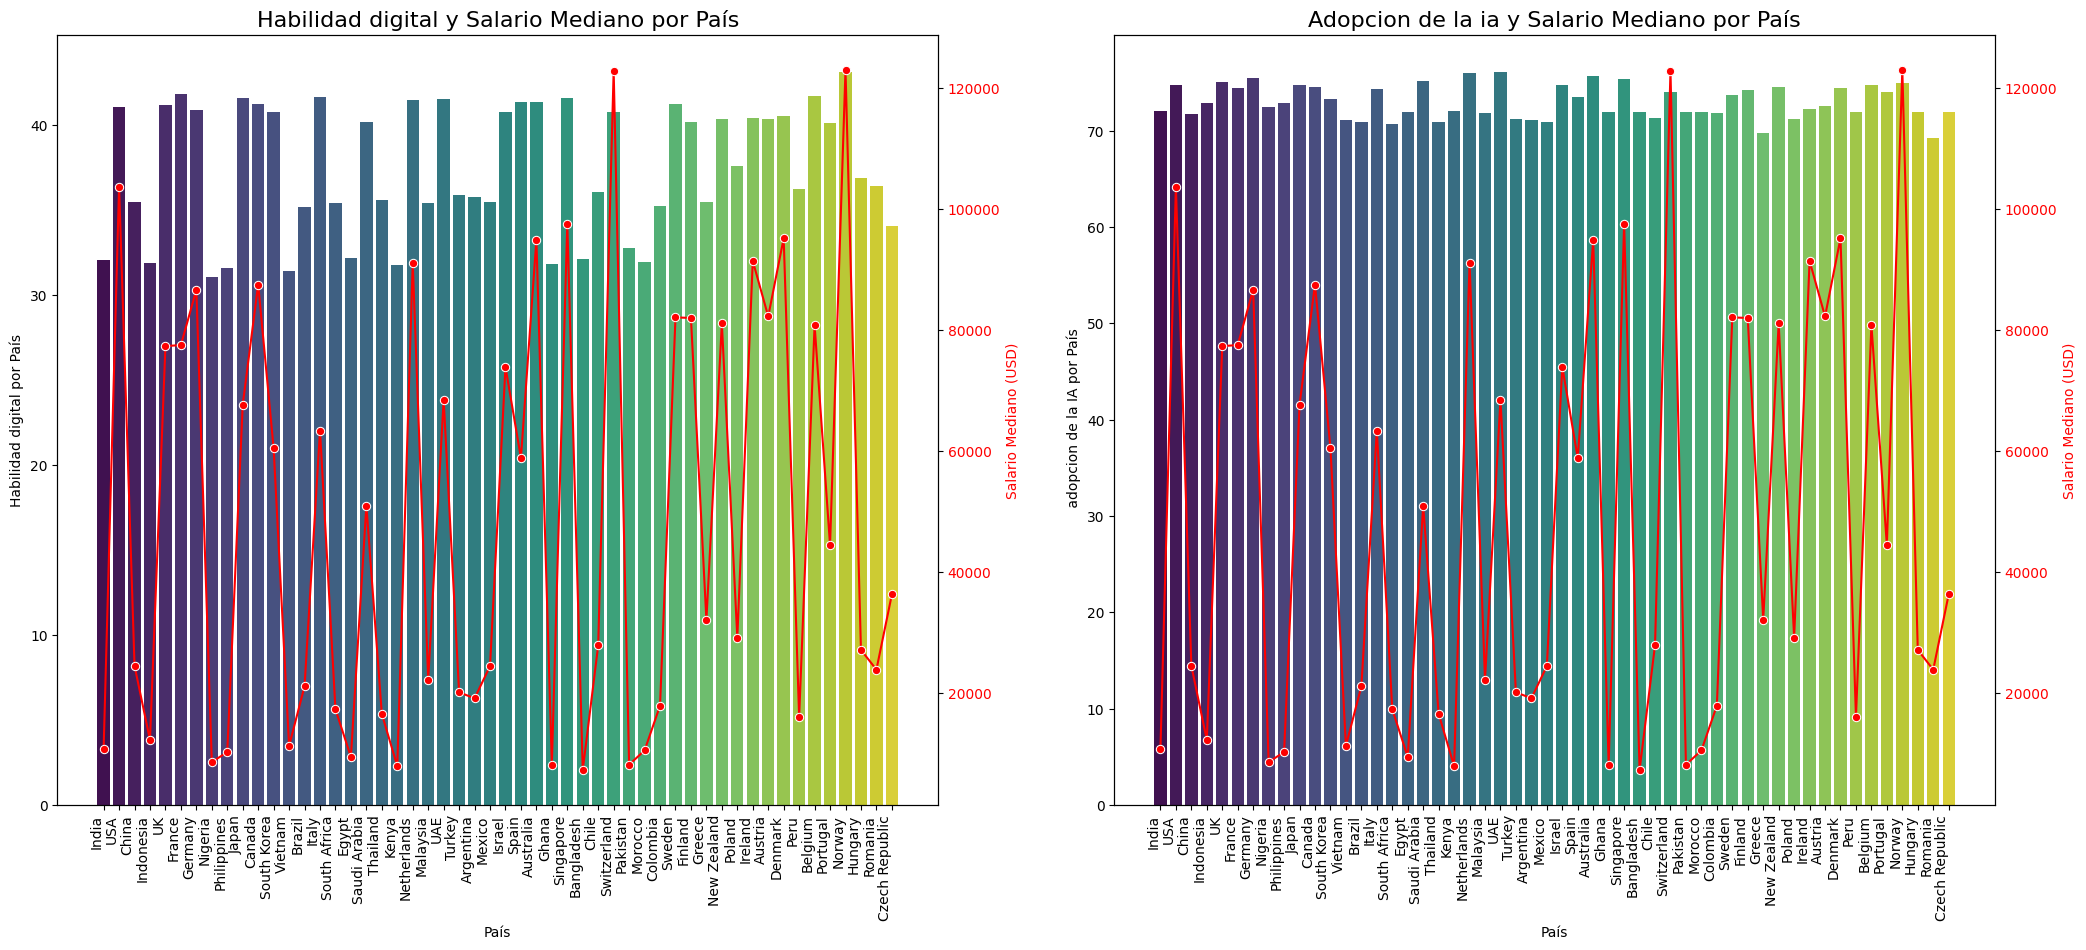

In [ ]:


# Creamos una figura con dos subplots (1 fila, 2 columnas)
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(25, 10))
sns.barplot(x='pais', y='habilidad_pais', data=df_plot2, palette='viridis', ax=ax1, hue='pais', legend=False)
ax1.set_xlabel('País')
ax1.set_ylabel('Habilidad digital por País', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_title('Habilidad digital y Salario Mediano por País', fontsize=16)
ax1.set_xticklabels(df_plot2['pais'], rotation=90, ha='right')

ax2 = ax1.twinx() # Creamos un segundo eje Y para el salario
sns.lineplot(x='pais', y='pais_salario', data=df_plot2, color='red', marker='o', ax=ax2, sort=False)
ax2.set_ylabel('Salario Mediano (USD)', color='red')
ax2.tick_params(axis='y', labelcolor='red')


sns.barplot(x='pais', y='adopcion_pais_ia', data=df_plot2, palette='viridis', ax=ax3, hue='pais', legend=False)
ax3.set_xlabel('País')
ax3.set_ylabel(' adopcion de la IA por País', color='black')
ax3.tick_params(axis='y', labelcolor='black')
ax3.set_title('Adopcion de la ia y Salario Mediano por País', fontsize=16)
ax3.set_xticklabels(df_plot2['pais'], rotation=90, ha='right')

ax2 = ax3.twinx() # Creamos un segundo eje Y para el salario
sns.lineplot(x='pais', y='pais_salario', data=df_plot2, color='red', marker='o', ax=ax2, sort=False)
ax2.set_ylabel('Salario Mediano (USD)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

Realizando el analisis de cada pais no varia mucho el salario conforme su habilidad a excepción de pocos paises, de echo diria que en la mayoria aunque tengan un nivel alto de uso de ia y habilidad digital no cambia su salario como es en caso de México, esto se puede ver claramente en la matriz de correlación más adelante

# Categoria textuales

In [ ]:
#Se revisara que categoria tiene cada columna categorica  de interes
print(columnas_textuales) #--sacamos de estas columnas, genero, rol_trabajo, tipo_empleo
categoria_rol_trabajo= df_nuevo2[['rol_trabajo']].value_counts()
print(50* '-')
print(categoria_rol_trabajo)
print(50* '-')
categoria_genero= df_nuevo2[['genero']].value_counts()
print(categoria_genero)
print(50* '-')
categoria_tipo_empleo= df_nuevo2[['tipo_empleo']].value_counts()
print(categoria_tipo_empleo)

Index(['pais', 'continente', 'genero', 'nivel_educativo', 'industria',
       'rol_trabajo', 'tipo_empleo', 'trabajo_remoto',
       'capacitacion_constante', 'estatus_empleo_ia'],
      dtype='object')
--------------------------------------------------
rol_trabajo              
Network Engineer             1991
Welder                        595
UI/UX Designer                579
Machine Learning Engineer     556
IT Support Specialist         554
                             ... 
Train Conductor               148
Transportation Planner        147
Delivery Driver               141
Shipping Coordinator          141
Port Operations Manager       140
Name: count, Length: 298, dtype: int64
--------------------------------------------------
genero
Female    46107
Male      44480
Other      1784
Name: count, dtype: int64
--------------------------------------------------
tipo_empleo
Full-time      64671
Part-time      11129
Contract       10859
Freelance       5712
Name: count, dtype: int64


* Vamos a identificar que género  predomina en el dataframe

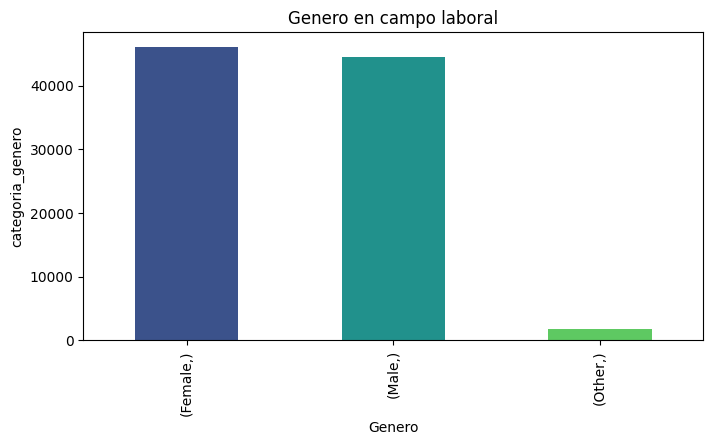

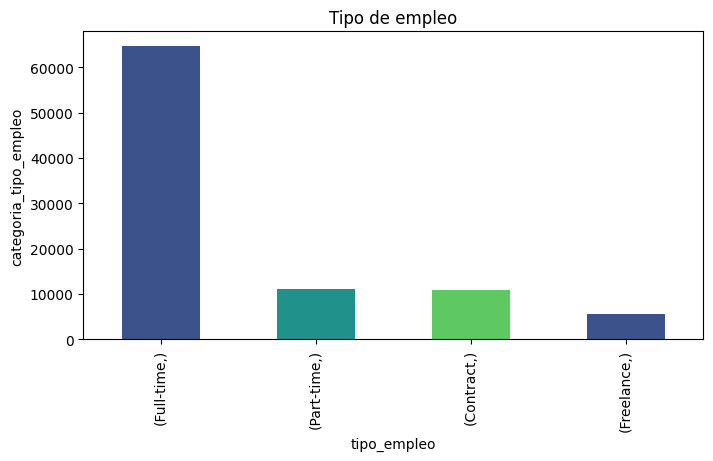

In [ ]:
colors1 = sns.color_palette('viridis', len(categoria_genero))
categoria_genero.plot(kind="bar", figsize=(8,4),  color=colors1)
plt.title("Genero en campo laboral")
plt.xlabel("Genero")
plt.ylabel("categoria_genero")
plt.show()

categoria_tipo_empleo.plot(kind="bar", figsize=(8,4), color=colors1)
plt.title("Tipo de empleo")
plt.xlabel("tipo_empleo")
plt.ylabel("categoria_tipo_empleo")
plt.show()


Vemos con esto que en nuestro data set predominan las mujeres y empleos de tiempo completo, además de que tenemos la modalidad freelance más bajo

In [ ]:
categoria_industria= df_nuevo2[['industria']].value_counts()
print(categoria_industria) #-- Vemos que efectivamente tenemos más en TI pero vamos a realizar una agrupacion


industria         
IT                    11652
Media                  8475
Energy                 7736
Healthcare             7178
Hospitality            6837
Manufacturing          6459
Education              6408
Finance                6190
Retail                 5038
Government             5014
Agriculture            4966
Legal                  4805
Construction           4771
Telecommunications     3642
Transportation         3200
Name: count, dtype: int64


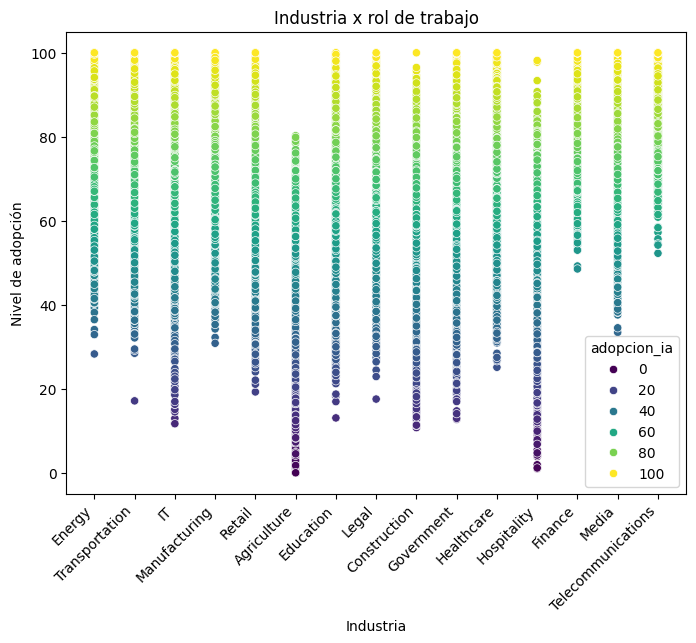

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_nuevo2,
    x="industria",
    y="adopcion_ia",
    hue="adopcion_ia",
    palette="viridis",
)

plt.title("Industria x rol de trabajo")
plt.xlabel("Industria")
plt.ylabel("Nivel de adopción")
plt.xticks(rotation=45, ha='right')
plt.show()

Identificamos que la adopción de IA en la industria es necesaria en casí todas a excepción agricultura y ámbito hospitalario  que no tiene una adopción de casí el 100%

# Relación de categorias numericas

In [ ]:
#Vamos a verificar la relacion  mediante una correlación
corr=df_nuevo2.select_dtypes(include="number").corr()
print(corr)

                                  año      edad  años_experiencia   salario  \
año                          1.000000  0.003616          0.003333  0.009553   
edad                         0.003616  1.000000          0.753405  0.082128   
años_experiencia             0.003333  0.753405          1.000000  0.033073   
salario                      0.009553  0.082128          0.033073  1.000000   
adopcion_ia                  0.375665  0.001731          0.002978  0.318166   
conocimiento_ia              0.030276 -0.225027         -0.287517  0.364097   
habilidad_digital            0.025879 -0.196424         -0.252271  0.359221   
productividad                0.071312  0.287018          0.285285  0.351379   
trabajo_semana               0.003407  0.001090         -0.001108  0.163697   
tiempo_formacion             0.179528  0.000111          0.001123  0.274772   
probabilidad_automatizacion  0.180941  0.055383          0.073546 -0.088238   
probabilidad_asenso          0.051576  0.088309     

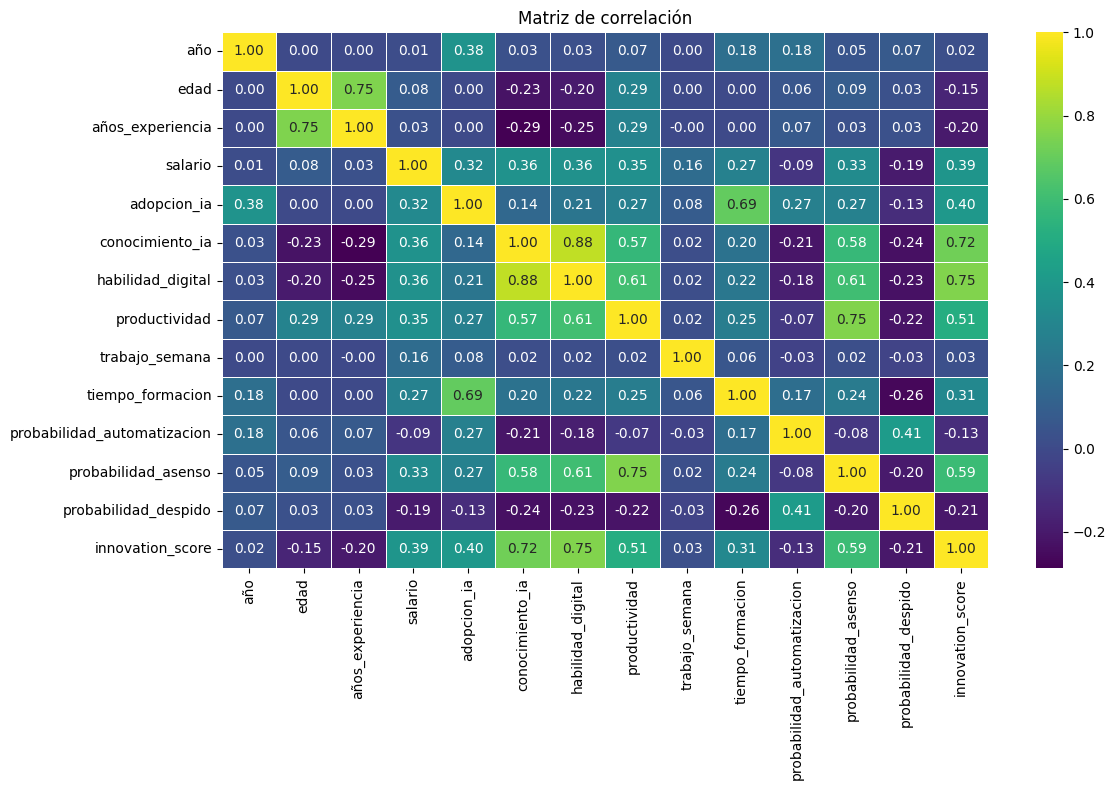

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="viridis",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

Podemos notar que la mayor relacion de nuestras columnas numericas son:


*   tiempo_formacion -adopcion_ai
*   edad - años de experiencia
*   innovacion_score -conocimiento_ai
*   innovacion_score - habilidad_digital
Tambien tenemos puntos que nos indica que hay relacion con la productividad entre más conocimiento y habilidad digital aumenta la productividad.
El salario en depende igual de estas variables y de la productividad por ende podemos decir
Para mayor salario = productividad, habilidad y conocimiento.



In [ ]:
df_nuevo2.head()

,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,14288.80,...,64.25,37.7,136.0,No,0.44,0.55,0.14,Employed,46.19,1
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,92290.01,...,46.15,41.6,55.5,Yes,0.48,0.48,0.21,Employed,59.25,0
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,12359.08,...,38.16,42.3,110.8,No,0.46,0.36,0.14,Employed,16.69,1
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,15811.44,...,76.66,40.0,109.7,Yes,0.69,0.35,0.27,Employed,39.84,1
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,9951.72,...,64.97,31.3,71.3,Yes,0.37,0.48,0.13,Employed,47.53,1


## Modelos
Primero voy a realizar un modelo de aprendizaje no supervisado para clasificar por grupos y entende mejor sus caracteristicas de cada grupo de datos, adicional replique dos graficas para observar su compartamiento ahora con los grupos.

Debido a que ya tengo los datos limpios ha sido más fácil ejecutar los modelos.

In [ ]:
from sklearn.cluster import KMeans
display(df_nuevo2)

,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,habilidad_digital,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.00,14288.80,...,39.60,64.25,37.7,136.0,No,0.44,0.55,0.14,Employed,46.19
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.00,92290.01,...,38.48,46.15,41.6,55.5,Yes,0.48,0.48,0.21,Employed,59.25
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.00,12359.08,...,7.28,38.16,42.3,110.8,No,0.46,0.36,0.14,Employed,16.69
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.00,15811.44,...,40.89,76.66,40.0,109.7,Yes,0.69,0.35,0.27,Employed,39.84
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.00,9951.72,...,39.41,64.97,31.3,71.3,Yes,0.37,0.48,0.13,Employed,47.53
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92366,Philippines,Asia,2031,63.0,Female,High School,Energy,Renewable Energy Consultant,14.00,13954.52,...,0.43,20.93,32.8,136.7,No,0.62,0.38,0.37,Unemployed,15.21
92367,Japan,Asia,2027,57.0,Male,Master,Manufacturing,Robotics Technician,13.00,71806.91,...,48.82,70.59,42.1,63.9,No,0.61,0.58,0.46,Career Change,54.24
92368,India,Asia,2027,23.0,Female,High School,Hospitality,Travel Agent,10.36,4739.71,...,23.48,12.81,33.6,72.2,Yes,0.30,0.16,0.21,Employed,0.00
92369,Brazil,South America,2024,35.0,Male,Diploma,Media,Social Media Manager,8.00,9991.31,...,26.21,50.50,27.8,48.3,No,0.26,0.44,0.12,Employed,59.79


* Uso el modelo Kmeans para categorizar por 5 grupos


In [ ]:
modelo = KMeans(
    n_clusters=5,
    random_state=42
)

# Seleccionar solo las columnas numéricas para el clustering
df_numerico = df_nuevo2.select_dtypes(include=[np.number])

modelo.fit(df_numerico)
df_nuevo2["Grupo"] = modelo.labels_

df_nuevo2.head()

,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,14288.80,...,64.25,37.7,136.0,No,0.44,0.55,0.14,Employed,46.19,1
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,92290.01,...,46.15,41.6,55.5,Yes,0.48,0.48,0.21,Employed,59.25,0
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,12359.08,...,38.16,42.3,110.8,No,0.46,0.36,0.14,Employed,16.69,1
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,15811.44,...,76.66,40.0,109.7,Yes,0.69,0.35,0.27,Employed,39.84,1
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,9951.72,...,64.97,31.3,71.3,Yes,0.37,0.48,0.13,Employed,47.53,1


Aquí podemos ver que tipo de registros tenemos por grupo

In [ ]:
for i in sorted(df_nuevo2['Grupo'].unique()):
    print(f"\nRegistros para el Grupo {i}:")
    display(df_nuevo2[df_nuevo2['Grupo'] == i].head())


Registros para el Grupo 0:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,92290.01,...,46.15,41.6,55.5,Yes,0.48,0.48,0.21,Employed,59.25,0
5,Australia,Oceania,2028,42.0,Male,Bachelor,Manufacturing,Quality Control Inspector,10.0,109313.44,...,69.02,54.0,121.8,Yes,0.82,0.47,0.27,Employed,57.15,0
7,Saudi Arabia,Asia,2024,46.0,Female,Master,IT,Machine Learning Engineer,15.0,122041.83,...,73.87,47.5,129.8,No,0.30,0.56,0.15,Employed,84.20,0
12,Israel,Asia,2034,24.0,Female,Master,Legal,Judge,0.0,107113.73,...,65.27,48.5,97.3,Yes,0.19,0.58,0.00,Employed,76.43,0
24,UK,Europe,2026,35.0,Male,Bachelor,Finance,Finance Manager,4.0,92983.11,...,59.34,41.6,82.3,No,0.34,0.49,0.19,Reskilled,52.74,0



Registros para el Grupo 1:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,14288.80,...,64.25,37.7,136.0,No,0.44,0.55,0.14,Employed,46.19,1
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,12359.08,...,38.16,42.3,110.8,No,0.46,0.36,0.14,Employed,16.69,1
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,15811.44,...,76.66,40.0,109.7,Yes,0.69,0.35,0.27,Employed,39.84,1
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,9951.72,...,64.97,31.3,71.3,Yes,0.37,0.48,0.13,Employed,47.53,1
6,Pakistan,Asia,2031,28.0,Male,Master,Energy,Renewable Energy Consultant,1.0,13809.42,...,59.98,36.2,123.9,Yes,0.34,0.43,0.00,Employed,49.42,1



Registros para el Grupo 2:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
20,Switzerland,Europe,2027,59.0,Male,PhD,Healthcare,Optometrist,8.00,216143.48,...,74.16,35.1,83.7,No,0.18,0.48,0.19,Employed,57.52,2
66,Denmark,Europe,2034,22.0,Male,Bachelor,IT,IT Support Specialist,10.36,213620.07,...,55.92,51.3,119.3,No,0.27,0.49,0.13,Employed,69.71,2
118,USA,North America,2026,34.0,Female,PhD,Telecommunications,VoIP Engineer,4.00,267517.71,...,64.17,32.3,100.8,No,0.29,0.59,0.00,Employed,67.76,2
155,USA,North America,2027,59.0,Male,Bachelor,Finance,Budget Analyst,13.00,213239.30,...,70.50,29.8,90.5,No,0.35,0.46,0.25,Career Change,46.58,2
212,USA,North America,2028,42.0,Male,Master,IT,IT Project Manager,15.00,236234.78,...,77.45,47.5,87.9,Yes,0.16,0.52,0.00,Employed,85.84,2



Registros para el Grupo 3:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
14,Germany,Europe,2033,26.0,Male,Master,Government,Civil Servant,1.0,130438.04,...,68.50,39.6,129.8,Yes,0.26,0.56,0.06,Reskilled,75.10,3
17,Israel,Asia,2022,55.0,Male,Bachelor,IT,Product Manager,21.0,150194.28,...,72.94,40.6,109.6,No,0.42,0.52,0.00,Employed,65.34,3
33,UK,Europe,2034,65.0,Female,Master,IT,IT Project Manager,22.0,148900.82,...,77.84,35.0,70.6,No,0.38,0.59,0.21,Employed,87.55,3
44,Belgium,Europe,2024,44.0,Male,Master,Healthcare,Anesthesiologist,4.0,170689.36,...,50.58,50.6,109.8,Yes,0.21,0.36,0.00,Employed,45.08,3
49,USA,North America,2020,52.0,Male,Master,IT,Solutions Architect,11.0,155411.88,...,58.57,19.1,72.1,No,0.27,0.43,0.12,Employed,72.07,3



Registros para el Grupo 4:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
16,Canada,North America,2024,36.0,Female,Bachelor,Retail,Warehouse Associate,2.0,58402.53,...,55.49,40.2,57.2,No,0.37,0.53,0.28,Career Change,31.04,4
18,Singapore,Asia,2029,19.0,Male,Bachelor,Manufacturing,Production Planner,0.0,57743.04,...,39.46,45.5,71.8,No,0.68,0.48,0.39,Unemployed,43.62,4
27,Chile,South America,2033,31.0,Female,Bachelor,Government,Policy Analyst,8.0,45267.18,...,47.32,38.8,101.7,Yes,0.40,0.38,0.00,Employed,34.87,4
31,Portugal,Europe,2020,36.0,Female,Bachelor,Transportation,Bus Driver,4.0,34337.30,...,59.94,22.7,108.1,Yes,0.39,0.56,0.07,Employed,60.16,4
38,Denmark,Europe,2028,54.0,Male,High School,Manufacturing,Packaging Operator,32.0,58289.86,...,60.95,51.8,98.4,No,0.67,0.38,0.25,Employed,11.29,4


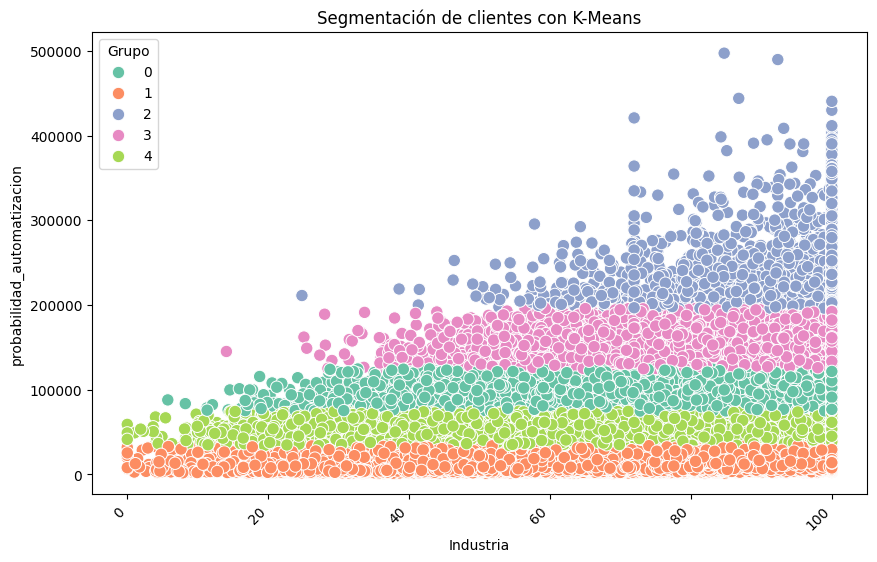

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_nuevo2,
    x="adopcion_ia",
    y="salario",
    hue="Grupo",
    palette="Set2",
    s=80
)
plt.xlabel("Industria")
plt.ylabel("probabilidad_automatizacion")
plt.xticks(rotation=45, ha='right')
plt.title("Segmentación de clientes con K-Means")

plt.show()

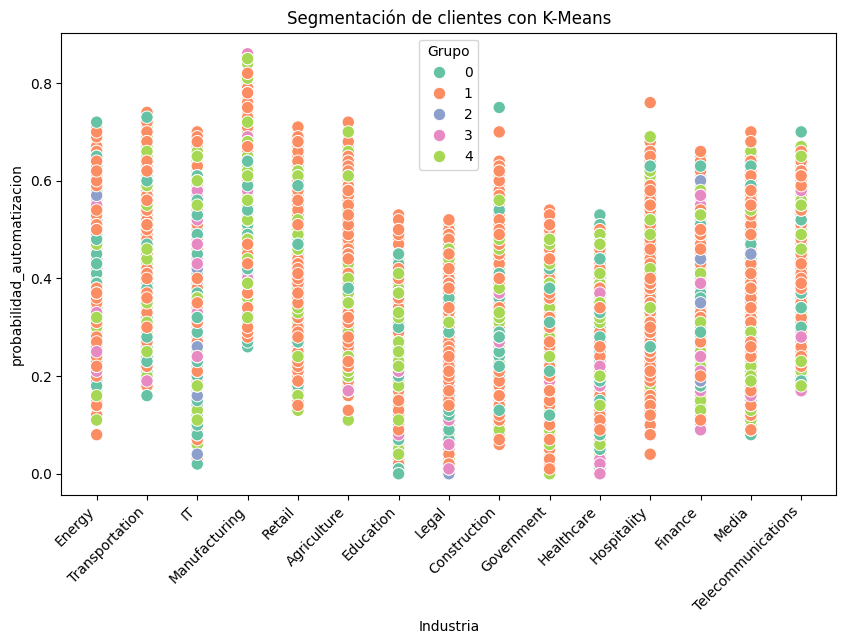

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df_nuevo2,
    x="industria",
    y="probabilidad_automatizacion",
    hue="Grupo",
    palette="Set2",
    s=80
)
plt.xlabel("Industria")
plt.ylabel("probabilidad_automatizacion")
plt.xticks(rotation=45, ha='right')
plt.title("Segmentación de clientes con K-Means")

plt.show()

Apartir de aquí voy a realizar una modelo supervisado para averigurar si hay ciertas condiciones en el aspecto laboral que nos lleve a ser reemplazado por la ia.

In [ ]:
for i in sorted(df_nuevo2['Grupo'].unique()):
    print(f"\nRegistros para el Grupo {i}:")
    display(df_nuevo2[df_nuevo2['Grupo'] == i].head())


Registros para el Grupo 0:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
1,Denmark,Europe,2035,58.0,Male,Bachelor,Transportation,Aviation Mechanic,13.0,92290.01,...,46.15,41.6,55.5,Yes,0.48,0.48,0.21,Employed,59.25,0
5,Australia,Oceania,2028,42.0,Male,Bachelor,Manufacturing,Quality Control Inspector,10.0,109313.44,...,69.02,54.0,121.8,Yes,0.82,0.47,0.27,Employed,57.15,0
7,Saudi Arabia,Asia,2024,46.0,Female,Master,IT,Machine Learning Engineer,15.0,122041.83,...,73.87,47.5,129.8,No,0.30,0.56,0.15,Employed,84.20,0
12,Israel,Asia,2034,24.0,Female,Master,Legal,Judge,0.0,107113.73,...,65.27,48.5,97.3,Yes,0.19,0.58,0.00,Employed,76.43,0
24,UK,Europe,2026,35.0,Male,Bachelor,Finance,Finance Manager,4.0,92983.11,...,59.34,41.6,82.3,No,0.34,0.49,0.19,Reskilled,52.74,0



Registros para el Grupo 1:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
0,Bangladesh,Asia,2035,36.0,Male,Bachelor,Energy,Energy Auditor,7.0,14288.80,...,64.25,37.7,136.0,No,0.44,0.55,0.14,Employed,46.19,1
2,Nigeria,Africa,2035,59.0,Female,High School,IT,DevOps Engineer,34.0,12359.08,...,38.16,42.3,110.8,No,0.46,0.36,0.14,Employed,16.69,1
3,Vietnam,Asia,2035,54.0,Female,Bachelor,Manufacturing,Production Supervisor,21.0,15811.44,...,76.66,40.0,109.7,Yes,0.69,0.35,0.27,Employed,39.84,1
4,Mexico,North America,2034,54.0,Female,Bachelor,Retail,Inventory Manager,13.0,9951.72,...,64.97,31.3,71.3,Yes,0.37,0.48,0.13,Employed,47.53,1
6,Pakistan,Asia,2031,28.0,Male,Master,Energy,Renewable Energy Consultant,1.0,13809.42,...,59.98,36.2,123.9,Yes,0.34,0.43,0.00,Employed,49.42,1



Registros para el Grupo 2:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
20,Switzerland,Europe,2027,59.0,Male,PhD,Healthcare,Optometrist,8.00,216143.48,...,74.16,35.1,83.7,No,0.18,0.48,0.19,Employed,57.52,2
66,Denmark,Europe,2034,22.0,Male,Bachelor,IT,IT Support Specialist,10.36,213620.07,...,55.92,51.3,119.3,No,0.27,0.49,0.13,Employed,69.71,2
118,USA,North America,2026,34.0,Female,PhD,Telecommunications,VoIP Engineer,4.00,267517.71,...,64.17,32.3,100.8,No,0.29,0.59,0.00,Employed,67.76,2
155,USA,North America,2027,59.0,Male,Bachelor,Finance,Budget Analyst,13.00,213239.30,...,70.50,29.8,90.5,No,0.35,0.46,0.25,Career Change,46.58,2
212,USA,North America,2028,42.0,Male,Master,IT,IT Project Manager,15.00,236234.78,...,77.45,47.5,87.9,Yes,0.16,0.52,0.00,Employed,85.84,2



Registros para el Grupo 3:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
14,Germany,Europe,2033,26.0,Male,Master,Government,Civil Servant,1.0,130438.04,...,68.50,39.6,129.8,Yes,0.26,0.56,0.06,Reskilled,75.10,3
17,Israel,Asia,2022,55.0,Male,Bachelor,IT,Product Manager,21.0,150194.28,...,72.94,40.6,109.6,No,0.42,0.52,0.00,Employed,65.34,3
33,UK,Europe,2034,65.0,Female,Master,IT,IT Project Manager,22.0,148900.82,...,77.84,35.0,70.6,No,0.38,0.59,0.21,Employed,87.55,3
44,Belgium,Europe,2024,44.0,Male,Master,Healthcare,Anesthesiologist,4.0,170689.36,...,50.58,50.6,109.8,Yes,0.21,0.36,0.00,Employed,45.08,3
49,USA,North America,2020,52.0,Male,Master,IT,Solutions Architect,11.0,155411.88,...,58.57,19.1,72.1,No,0.27,0.43,0.12,Employed,72.07,3



Registros para el Grupo 4:


,pais,continente,año,edad,genero,nivel_educativo,industria,rol_trabajo,años_experiencia,salario,...,productividad,trabajo_semana,tiempo_formacion,capacitacion_constante,probabilidad_automatizacion,probabilidad_asenso,probabilidad_despido,estatus_empleo_ia,innovation_score,Grupo
16,Canada,North America,2024,36.0,Female,Bachelor,Retail,Warehouse Associate,2.0,58402.53,...,55.49,40.2,57.2,No,0.37,0.53,0.28,Career Change,31.04,4
18,Singapore,Asia,2029,19.0,Male,Bachelor,Manufacturing,Production Planner,0.0,57743.04,...,39.46,45.5,71.8,No,0.68,0.48,0.39,Unemployed,43.62,4
27,Chile,South America,2033,31.0,Female,Bachelor,Government,Policy Analyst,8.0,45267.18,...,47.32,38.8,101.7,Yes,0.40,0.38,0.00,Employed,34.87,4
31,Portugal,Europe,2020,36.0,Female,Bachelor,Transportation,Bus Driver,4.0,34337.30,...,59.94,22.7,108.1,Yes,0.39,0.56,0.07,Employed,60.16,4
38,Denmark,Europe,2028,54.0,Male,High School,Manufacturing,Packaging Operator,32.0,58289.86,...,60.95,51.8,98.4,No,0.67,0.38,0.25,Employed,11.29,4


Modelo ramdom tree, se va a realizar un modelo supervisado para responder que tan probable es la automatización en los roles laborales

In [ ]:
from sklearn.model_selection import train_test_split
X= df_nuevo2[['habilidad_digital','productividad','probabilidad_automatizacion','probabilidad_despido']].fillna(0)

y=df_nuevo2['Grupo']

X.head()

,habilidad_digital,productividad,probabilidad_automatizacion,probabilidad_despido
0,39.60,64.25,0.44,0.14
1,38.48,46.15,0.48,0.21
2,7.28,38.16,0.46,0.14
3,40.89,76.66,0.69,0.27
4,39.41,64.97,0.37,0.13


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression()

modelo.fit(
    X_train,
    y_train
)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [ ]:
predicciones = modelo.predict(X_test)

predicciones[:10]

array([1, 3, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [ ]:
resultado = X_test.copy()
resultado["Real"] = y_test.values
resultado["Predicción"] = predicciones

resultado.head(10)

,habilidad_digital,productividad,probabilidad_automatizacion,probabilidad_despido,Real,Predicción
69947,45.31,49.65,0.21,0.11,4,1
60909,70.83,85.31,0.35,0.00,0,3
14614,37.12,40.68,0.40,0.08,1,1
59571,51.55,54.42,0.33,0.00,2,1
9908,52.27,59.68,0.46,0.27,1,1
18465,34.86,55.15,0.46,0.03,1,1
18647,20.25,65.89,0.39,0.14,1,1
64659,68.53,57.47,0.18,0.15,1,1
22753,41.94,51.02,0.28,0.03,1,1
39326,20.55,30.78,0.57,0.08,1,1


Evaluación

In [ ]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(
    y_test,
    predicciones
)

print(matriz)

[[  166  3849     0   212     0]
 [  229 13499     0   247     0]
 [   92   456     0   156     0]
 [  156  1832     0   244     0]
 [  166  6161     0   247     0]]


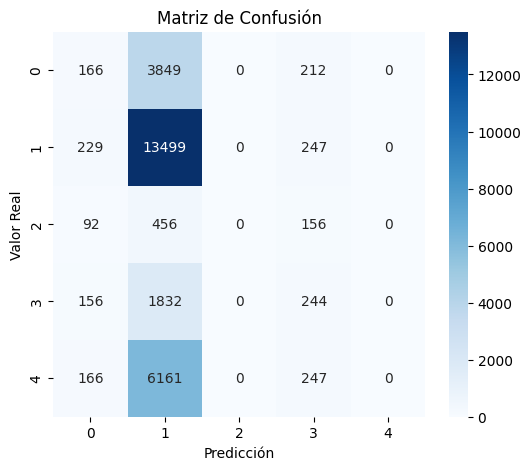

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicción")

plt.ylabel("Valor Real")

plt.title("Matriz de Confusión")

plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(f"Accuracy : {accuracy_score(y_test, predicciones):.2f}")
print(f"Precision: {precision_score(y_test, predicciones, average='weighted'):.2f}")
print(f"Recall   : {recall_score(y_test, predicciones, average='weighted'):.2f}")
print(f"F1 Score : {f1_score(y_test, predicciones, average='weighted'):.2f}")

Accuracy : 0.50
Precision: 0.31
Recall   : 0.50
F1 Score : 0.36


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np

# Obtener las probabilidades de predicción para todas las clases
probabilidades = modelo.predict_proba(X_test)

# Binarizar las etiquetas reales para la estrategia "uno contra el resto"
# Obtener las clases únicas de y_test para asegurar que todas estén representadas
classes = np.unique(y_test)
y_test_binarized = label_binarize(y_test, classes=classes)

In [ ]:
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(len(classes)): #Calculo de roc aleatoria
    fpr[i], tpr[i], _ = roc_curve(y_test_binarized[:, i], probabilidades[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

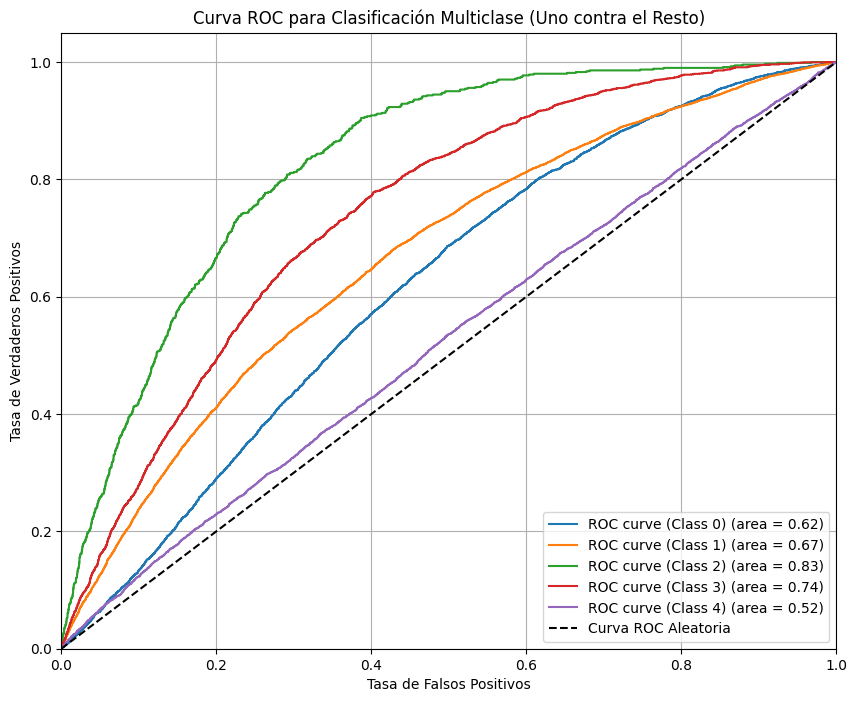

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for i in range(len(classes)):
    plt.plot(fpr[i], tpr[i], label=f'ROC curve (Class {classes[i]}) (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Curva ROC Aleatoria') # Curva ROC de un clasificador aleatorio

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC para Clasificación Multiclase (Uno contra el Resto)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Conclusiones del Análisis de Curvas ROC y AUC por Grupo


---


Grupo	AUC	Interpretación del Rendimiento
1. 0	0.62	| Rendimiento Moderado: El modelo tiene una capacidad aceptable para distinguir esta clase, mejor que el azar, pero con margen de mejora.

2. 1	0.67	| Rendimiento Moderado: Similar al Grupo 0, el modelo muestra un rendimiento razonable, indicando que las características tienen cierto poder predictivo, pero no son altamente discriminatorias.

3. 2	0.83	| Buen Rendimiento: El modelo es bastante efectivo para identificar y diferenciar esta clase del resto, lo que sugiere que las características seleccionadas son robustas para predecir este grupo.

4. 3	0.74 | Rendimiento Aceptable: El modelo clasifica bien este grupo, con un buen equilibrio entre la tasa de verdaderos positivos y la tasa de falsos positivos.
5. 4	0.52 |	Rendimiento Deficiente: El modelo apenas supera la clasificación aleatoria (AUC de 0.5), indicando que tiene grandes dificultades para distinguir esta clase. Es el grupo más difícil de predecir con las características actuales.

Conclusión General:

El modelo de regresión logística exhibe un rendimiento variado. Es particularmente bueno para predecir el Grupo 2, lo que podría indicar que este grupo tiene características muy distintivas que facilitan su identificación. Sin embargo, para el Grupo 4, el modelo casi no aporta valor predictivo significativo, sugiriendo que las características actuales son insuficientes o que el grupo es demasiado complejo.

Con esto se realizo dos modelos agrupando los datos que son variados para verificar como puedo predecir que pertenencen a cierto grupo, esto con la finalidad de analizar que caracteristican comparten
Se plantea trabajar con random forest más adelante pero por cuestiones de capacidad de mi equipo trabaje con estos básicos.
